# GPU performance

This notebook needs an NVIDIA GPU. It does not import anything from `src/`, so it can run on its own:

- **locally**, after `uv sync --group gpu`;
- **in Google Colab**: *File → Upload notebook*, then *Runtime → Change runtime type → T4 GPU*.

Colab's T4 is older and slower than a recent desktop GPU, but the conclusions are the same.

## Environment

In Colab, PyTorch is already installed, and CuPy (used for the CUDA kernel below) is installed if missing. Locally, this cell does nothing.

In [ ]:
import importlib.util
import subprocess
import sys

running_in_colab = "google.colab" in sys.modules
if running_in_colab and importlib.util.find_spec("cupy") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", "cupy-cuda12x"], check=True)

In [ ]:
import torch

if not torch.cuda.is_available():
    raise RuntimeError("No CUDA GPU found. Run this notebook in Colab with a GPU runtime, "
                       "or read it together with the reference results in language_landscape.md.")

device_properties = torch.cuda.get_device_properties(0)
{
    "name": device_properties.name,
    "streaming multiprocessors": device_properties.multi_processor_count,
    "memory (GB)": round(device_properties.total_memory / 1e9, 1),
}

{'name': 'NVIDIA GeForce RTX 5060 Ti',
 'streaming multiprocessors': 36,
 'memory (GB)': 16.6}

## Moving data to the GPU

The GPU has **its own memory**, separate from the computer's RAM. In CUDA terms, the CPU side is the **host** and the GPU side is the **device**. Data must be copied to the device before the GPU can use it, and results copied back.

In PyTorch, arrays are called **tensors** (notebook 02), and `.to("cuda")` copies a tensor to the GPU. Our test matrices are 4096 × 4096 float32 values: 64 MB each.

In [ ]:
n = 4096
cpu_a = torch.randn(n, n, dtype=torch.float32)
cpu_b = torch.randn(n, n, dtype=torch.float32)

gpu_a = cpu_a.to("cuda")
gpu_b = cpu_b.to("cuda")
gpu_a.device, gpu_a.dtype, gpu_a.shape

(device(type='cuda', index=0), torch.float32, torch.Size([4096, 4096]))

## Timing GPU code correctly

GPU work is **asynchronous**: when Python asks the GPU to multiply, the call returns as soon as the work has been *queued*, while the GPU is still computing. A timer stopped right after the call measures almost nothing. To time GPU work correctly, we must **synchronise**, that is, wait until the GPU has finished, before reading the clock.

In [ ]:
import time

gpu_a @ gpu_b
torch.cuda.synchronize()

start = time.perf_counter()
gpu_a @ gpu_b
seconds_without_synchronize = time.perf_counter() - start
torch.cuda.synchronize()

start = time.perf_counter()
gpu_a @ gpu_b
torch.cuda.synchronize()
seconds_with_synchronize = time.perf_counter() - start

f"without synchronize: {seconds_without_synchronize * 1000:.3f} ms, with: {seconds_with_synchronize * 1000:.2f} ms"

'without synchronize: 0.088 ms, with: 8.45 ms'

The helper below applies what we learned: a warm-up run (the first call also pays one-off costs, such as loading the code onto the GPU), synchronisation after each run, and the median of several runs, as in `src/benchmark.py`. Performance on the GPU is large enough to be measured in **TFLOPS**: trillions (a thousand billion) of operations per second.

In [ ]:
import statistics
from collections.abc import Callable

def time_gpu(function: Callable[[], object], repeats: int = 10) -> float:
    function()
    torch.cuda.synchronize()
    measured_seconds = []
    for _ in range(repeats):
        start = time.perf_counter()
        function()
        torch.cuda.synchronize()
        measured_seconds.append(time.perf_counter() - start)
    return statistics.median(measured_seconds)

def tflops(n: int, seconds: float) -> float:
    return 2 * n**3 / seconds / 1e12

## The GPU against the CPU

PyTorch calls cuBLAS on the GPU and a BLAS library on the CPU, so this is a fair fight between two expert-tuned libraries, both in float32. (`torch.set_float32_matmul_precision("highest")` makes sure float32 is really used in full; the next section explains the alternative.)

In [ ]:
torch.set_float32_matmul_precision("highest")

gpu_seconds = time_gpu(lambda: gpu_a @ gpu_b)
cpu_measured_seconds = []
for _ in range(3):
    start = time.perf_counter()
    cpu_a @ cpu_b
    cpu_measured_seconds.append(time.perf_counter() - start)
cpu_seconds = statistics.median(cpu_measured_seconds)

{
    "CPU, all cores": f"{cpu_seconds * 1000:.0f} ms, {tflops(n, cpu_seconds):.2f} TFLOPS",
    "GPU": f"{gpu_seconds * 1000:.1f} ms, {tflops(n, gpu_seconds):.1f} TFLOPS",
}

{'CPU, all cores': '133 ms, 1.03 TFLOPS', 'GPU': '8.0 ms, 17.1 TFLOPS'}

In [ ]:
torch.allclose((gpu_a @ gpu_b).cpu(), cpu_a @ cpu_b, rtol=1e-3, atol=1e-3)

True

## Data transfer is not free

The GPU times above assume the matrices are already on the GPU. Copying data between the computer's memory and the GPU goes through the **PCIe bus**, the connection between them, which is far slower than the GPU's own memory.

In [ ]:
host_to_device_seconds = time_gpu(lambda: cpu_a.to("cuda"))
device_to_host_seconds = time_gpu(lambda: gpu_a.to("cpu"))
{
    "copy one matrix to the GPU": f"{host_to_device_seconds * 1000:.1f} ms",
    "copy one matrix back": f"{device_to_host_seconds * 1000:.1f} ms",
    "multiply two matrices on the GPU": f"{gpu_seconds * 1000:.1f} ms",
}

{'copy one matrix to the GPU': '3.0 ms',
 'copy one matrix back': '12.8 ms',
 'multiply two matrices on the GPU': '8.0 ms'}

Moving the data can take about as long as computing with it. That is why deep-learning frameworks move the model and the data to the GPU once (`model.to("cuda")`) and keep everything there, instead of copying back and forth for every operation.

## Precision: why AI uses smaller numbers

The deep dive [Numbers and memory](numbers_and_memory.ipynb) introduced float64, float32 and float16. On a GPU, the number format changes the speed dramatically:

- **float64**: consumer (gaming) GPUs have very few units for 64-bit numbers, a small fraction of their float32 speed. GPUs for data centres have more.
- **float32**: the standard format.
- **TF32** (*TensorFloat-32*): a trick of NVIDIA GPUs. The inputs are rounded internally to about 3 decimal digits so that the **tensor cores** (circuits specialised in multiplying small matrices, notebook 02) can process float32 data. PyTorch allows it with `torch.set_float32_matmul_precision("high")`.
- **float16** and **bfloat16**: 16-bit formats that run on tensor cores at full speed. **bfloat16** (*brain float*, designed at Google) keeps float32's range of values but with fewer digits, which makes it the usual choice for training.

For each format we measure the speed, and the error compared with a float64 result:

In [ ]:
reference_a, reference_b = gpu_a.double(), gpu_b.double()
reference_product = reference_a @ reference_b

precision_settings = {
    "float64": (torch.float64, "highest"),
    "float32": (torch.float32, "highest"),
    "TF32": (torch.float32, "high"),
    "float16": (torch.float16, "highest"),
    "bfloat16": (torch.bfloat16, "highest"),
}
precision_results = {}
for label, (dtype, float32_precision) in precision_settings.items():
    torch.set_float32_matmul_precision(float32_precision)
    converted_a, converted_b = reference_a.to(dtype), reference_b.to(dtype)
    seconds = time_gpu(lambda: converted_a @ converted_b)
    relative_error = ((converted_a @ converted_b).double() - reference_product).abs().max() / reference_product.abs().max()
    precision_results[label] = {"TFLOPS": round(tflops(n, seconds), 2), "relative error": f"{relative_error.item():.1e}"}
torch.set_float32_matmul_precision("highest")

precision_results

{'float64': {'TFLOPS': 0.36, 'relative error': '0.0e+00'},
 'float32': {'TFLOPS': 17.07, 'relative error': '2.9e-06'},
 'TF32': {'TFLOPS': 24.62, 'relative error': '2.9e-04'},
 'float16': {'TFLOPS': 49.23, 'relative error': '4.8e-04'},
 'bfloat16': {'TFLOPS': 50.05, 'relative error': '3.8e-03'}}

The float64 error is zero only because float64 is its own reference. Each step down in precision buys speed and costs accuracy.

Neural networks tolerate errors around $10^{-3}$ well: their weights are approximate anyway, and training is noisy by nature. That is why modern training uses **mixed precision**: 16-bit matrix multiplications, with sums and a master copy of the weights kept in float32. And, as the deep dive [Numbers and memory](numbers_and_memory.ipynb) showed, halving the size of every number also halves the memory a model needs.

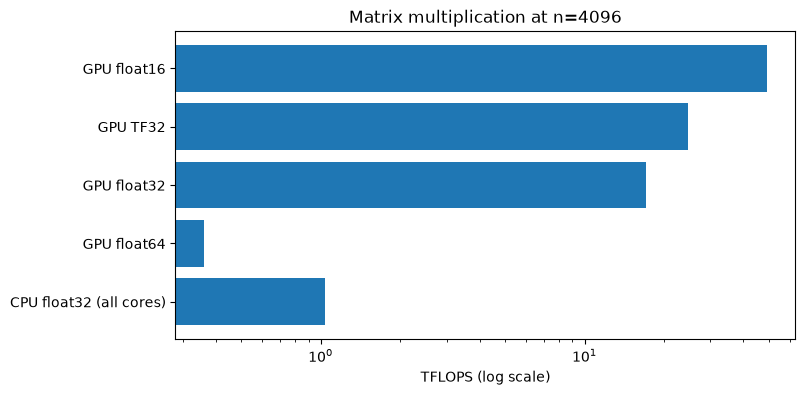

In [ ]:
import matplotlib.pyplot as plt

throughput = {
    "CPU float32 (all cores)": tflops(n, cpu_seconds),
    "GPU float64": precision_results["float64"]["TFLOPS"],
    "GPU float32": precision_results["float32"]["TFLOPS"],
    "GPU TF32": precision_results["TF32"]["TFLOPS"],
    "GPU float16": precision_results["float16"]["TFLOPS"],
}

figure, axis = plt.subplots(figsize=(8, 4))
axis.barh(list(throughput), list(throughput.values()))
axis.set_xscale("log")
axis.set_xlabel("TFLOPS (log scale)")
axis.set_title(f"Matrix multiplication at n={n}")
plt.show()

## Writing a CUDA kernel

A function that runs on the GPU is called a **kernel**. When it is launched, thousands of GPU threads run the same kernel code at once, each on different data, which it selects using its own index. Threads are organised in **blocks** (up to 1024 threads each), and blocks form a **grid**. The hardware runs threads in groups of 32 called **warps**, all executing the same instruction at the same time.

The kernel below is written in CUDA C, and each thread computes **one** element of the result: the three-loop algorithm with the two outer loops replaced by threads. **CuPy**, a NumPy-like library for GPUs, compiles it at run time with NVIDIA's run-time compiler, so no separate CUDA installation is needed.

In [ ]:
import cupy as cp

naive_kernel_source = r"""
extern "C" __global__
void matmul_naive(const float *a, const float *b, float *c, int n) {
    int row = blockIdx.y * blockDim.y + threadIdx.y;
    int column = blockIdx.x * blockDim.x + threadIdx.x;
    if (row < n && column < n) {
        float sum = 0.0f;
        for (int k = 0; k < n; k++) {
            sum += a[row * n + k] * b[k * n + column];
        }
        c[row * n + column] = sum;
    }
}
"""
matmul_naive_kernel = cp.RawKernel(naive_kernel_source, "matmul_naive")

Launching the kernel means choosing the block shape (16 × 16 = 256 threads) and how many blocks are needed to cover the matrix. For $n = 4096$ that is 65,536 blocks, and about 16.8 million threads. `cp.asarray` wraps the PyTorch tensors without copying them, since they are already on the GPU.

In [ ]:
import math

import numpy as np

THREADS_PER_BLOCK_SIDE = 16

def matmul_naive_cuda(matrix_a: cp.ndarray, matrix_b: cp.ndarray) -> cp.ndarray:
    size = matrix_a.shape[0]
    result = cp.empty((size, size), dtype=cp.float32)
    blocks_per_side = math.ceil(size / THREADS_PER_BLOCK_SIDE)
    matmul_naive_kernel((blocks_per_side, blocks_per_side), (THREADS_PER_BLOCK_SIDE, THREADS_PER_BLOCK_SIDE),
                        (matrix_a, matrix_b, result, np.int32(size)))
    return result

cupy_a, cupy_b = cp.asarray(gpu_a), cp.asarray(gpu_b)
cp.allclose(matmul_naive_cuda(cupy_a, cupy_b), cp.asarray(gpu_a @ gpu_b), rtol=1e-3, atol=1e-3).item()

True

In [ ]:
naive_seconds = time_gpu(lambda: matmul_naive_cuda(cupy_a, cupy_b))
{
    "naive CUDA kernel": f"{tflops(n, naive_seconds):.2f} TFLOPS",
    "cuBLAS (via PyTorch)": f"{tflops(n, gpu_seconds):.2f} TFLOPS",
    "CPU BLAS, all cores": f"{tflops(n, cpu_seconds):.2f} TFLOPS",
}

{'naive CUDA kernel': '1.53 TFLOPS',
 'cuBLAS (via PyTorch)': '17.11 TFLOPS',
 'CPU BLAS, all cores': '1.03 TFLOPS'}

The naive kernel is far behind cuBLAS, and on a machine with a strong CPU it may not even beat CPU BLAS. Thousands of cores do not help much when every thread keeps re-reading the same values from the GPU's main memory. cuBLAS uses the same ideas as CPU BLAS (notebook 04): tiles loaded into fast on-chip memory, reused many times, and tensor cores. **The hardware alone does not win; the library does.**

## GPU kernels in Python with Triton

Writing a CUDA kernel that competes with cuBLAS requires expert knowledge. **Triton** (developed at OpenAI, open source) is a language embedded in Python that works at a higher level: each program instance processes a whole **block** of the matrix, and the Triton compiler decides how to use threads, fast memory and tensor cores. `torch.compile`, PyTorch's compiler, generates Triton code automatically. Triton needs Linux and a recent GPU; skip this section if it fails on an older one.

The kernel below is a simplified version of the official Triton tutorial. Each program instance computes one 128 × 128 tile of the result, walking along the shared dimension in steps of 64 and multiplying tiles with `tl.dot`, which uses the tensor cores. It works in float16.

In [ ]:
import triton
import triton.language as tl

@triton.jit
def matmul_triton_kernel(a_pointer, b_pointer, c_pointer, n,
                         BLOCK_SIZE_M: tl.constexpr, BLOCK_SIZE_N: tl.constexpr, BLOCK_SIZE_K: tl.constexpr):
    row_offsets = tl.program_id(axis=0) * BLOCK_SIZE_M + tl.arange(0, BLOCK_SIZE_M)
    column_offsets = tl.program_id(axis=1) * BLOCK_SIZE_N + tl.arange(0, BLOCK_SIZE_N)
    k_offsets = tl.arange(0, BLOCK_SIZE_K)
    # 2D blocks of pointers: rows of a combined with k, and k combined with columns of b
    a_tile_pointers = a_pointer + row_offsets[:, None] * n + k_offsets[None, :]
    b_tile_pointers = b_pointer + k_offsets[:, None] * n + column_offsets[None, :]

    accumulator = tl.zeros((BLOCK_SIZE_M, BLOCK_SIZE_N), dtype=tl.float32)
    for k_start in range(0, n, BLOCK_SIZE_K):
        a_tile = tl.load(a_tile_pointers, mask=(row_offsets[:, None] < n) & (k_offsets[None, :] + k_start < n), other=0.0)
        b_tile = tl.load(b_tile_pointers, mask=(k_offsets[:, None] + k_start < n) & (column_offsets[None, :] < n), other=0.0)
        accumulator = tl.dot(a_tile, b_tile, accumulator)
        a_tile_pointers += BLOCK_SIZE_K
        b_tile_pointers += BLOCK_SIZE_K * n

    c_tile_pointers = c_pointer + row_offsets[:, None] * n + column_offsets[None, :]
    tl.store(c_tile_pointers, accumulator.to(tl.float16), mask=(row_offsets[:, None] < n) & (column_offsets[None, :] < n))

In [ ]:
TILE_M, TILE_N, TILE_K = 128, 128, 64

def matmul_triton(matrix_a: torch.Tensor, matrix_b: torch.Tensor) -> torch.Tensor:
    size = matrix_a.shape[0]
    result = torch.empty_like(matrix_a)
    grid = (triton.cdiv(size, TILE_M), triton.cdiv(size, TILE_N))
    matmul_triton_kernel[grid](matrix_a, matrix_b, result, size,
                               BLOCK_SIZE_M=TILE_M, BLOCK_SIZE_N=TILE_N, BLOCK_SIZE_K=TILE_K)
    return result

half_a, half_b = gpu_a.half(), gpu_b.half()
torch.allclose(matmul_triton(half_a, half_b).float(), (half_a @ half_b).float(), rtol=1e-2, atol=1e-1)

True

In [ ]:
triton_seconds = time_gpu(lambda: matmul_triton(half_a, half_b))
{"Triton float16": f"{tflops(n, triton_seconds):.1f} TFLOPS",
 "cuBLAS float16": f"{precision_results['float16']['TFLOPS']:.1f} TFLOPS"}

{'Triton float16': '47.3 TFLOPS', 'cuBLAS float16': '49.2 TFLOPS'}

About twenty lines of Python-like code come close to NVIDIA's own library. It is the pattern of the whole series, one level lower: Python as the language in which people *express* computations, compiled down to code that uses the hardware to its limits.

## Key ideas

- GPU work is **asynchronous**: always synchronise before stopping a timer, and warm up first.
- Copying data between the computer's memory and the GPU is slow, so frameworks keep models and data on the GPU.
- Lower-precision formats (TF32, float16, bfloat16) run on **tensor cores**, several times faster, at the cost of small errors that AI tolerates.
- GPU threads run in groups of 32 (**warps**); a simple kernel is far behind cuBLAS, while **Triton** gets close to it with a few lines of Python.